# Task 2: Modeling — Credit Card Data (`creditcard.csv`)

Goal: build and compare a baseline (Logistic Regression) against an ensemble (LightGBM) on the credit card fraud data, evaluated on the **untouched, imbalanced test set**. Same template as `modeling_fraud.ipynb`, so results are directly comparable.

**Notebook map**
1. Load, restore column names, sanity-check
2. Metric selection
3. Baseline: Logistic Regression
4. Ensemble: LightGBM (SMOTE arm and class-weight arm)
5. Evaluation
6. Observations and save outputs

**Two properties of this dataset shape everything below**
- Fraud is about 0.17% of the test set, which is only around 95 fraud cases. Metrics computed on so few positives are noisy; small differences between models should not be over-read.
- SMOTE took roughly 380 real fraud rows in train and expanded them to about 226K, so over 99.8% of the resampled fraud class is synthetic. This is the main overfitting risk to watch.

In [1]:
import os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

# --- Paths: assumes this notebook lives in <repo>/notebooks/ ---
PROJECT_ROOT = Path("..")
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

sys.path.append(str(PROJECT_ROOT / "src"))
from modeling_utils import evaluate_model, plot_pr_curves

RANDOM_STATE = 42

## 1. Load, restore column names, sanity-check
The saved credit card arrays have no column names (they were saved as numpy arrays). Names are restored here so that feature importance and SHAP in Task 3 are readable.

In [2]:
cc_resampled = joblib.load(DATA_DIR / "creditcard_train_resampled.pkl")
cc_split = joblib.load(DATA_DIR / "creditcard_train_test_split.pkl")

X_train_cc_res, y_train_cc_res = cc_resampled
X_train_cc, X_test_cc, y_train_cc, y_test_cc = cc_split

print(f"Train (original):   {X_train_cc.shape}")
print(f"Train (resampled):  {X_train_cc_res.shape}")
print(f"Test:               {X_test_cc.shape}")
print(type(X_train_cc_res))

Train (original):   (226980, 31)
Train (resampled):  (453204, 31)
Test:               (56746, 31)
<class 'numpy.ndarray'>


**Restoring column names.** The saved arrays have 31 columns. Profiling them showed this layout:
- column 0: `Time` (seconds, range 0 to about 172,792, unscaled)
- columns 1-28: `V1`..`V28` (std falls from about 1.95 to 0.33, i.e. PCA order, unscaled)
- column 29: an hour-of-day feature (integers 0 to 23)
- column 30: `Amount_log` (log scale, max under 10)

There is no raw `Amount` column in the arrays. A wrong order would silently mislabel every later plot, so the next cell verifies each assumption with hard checks before the names are applied.

In [3]:
cc_features = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["hour_of_day", "Amount_log"]
assert len(cc_features) == X_train_cc.shape[1] == X_train_cc_res.shape[1] == X_test_cc.shape[1] == 31

A = np.asarray(X_train_cc)

# V1..V28: PCA components, std should decrease from V1 to V28 (informational)
print("std of columns 1-28:", np.round(A[:, 1:29].std(axis=0), 2))

# Column 0 must be Time in seconds (dataset spans ~2 days = ~172,800 s)
assert A[:, 0].max() > 86_400, "Column 0 does not look like Time in seconds"

# Column 29 must be an integer hour of day (0-23)
assert np.allclose(A[:, 29], np.round(A[:, 29])) and A[:, 29].min() >= 0 and A[:, 29].max() <= 23,     "Column 29 is not an integer hour in 0-23"

# Column 30 must be on a log scale (non-negative, small max)
assert A[:, 30].min() >= 0 and A[:, 30].max() < 12, "Column 30 does not look like log(Amount)"

print("Column layout verified.")

std of columns 1-28: [1.95 1.65 1.51 1.42 1.36 1.32 1.2  1.17 1.09 1.07 1.02 0.99 0.99 0.95
 0.91 0.87 0.84 0.84 0.81 0.76 0.72 0.72 0.63 0.61 0.52 0.48 0.39 0.33]
Column layout verified.


In [4]:
if not isinstance(X_train_cc_res, pd.DataFrame):
    X_train_cc_res = pd.DataFrame(X_train_cc_res, columns=cc_features)
    X_train_cc = pd.DataFrame(X_train_cc, columns=cc_features)
    X_test_cc = pd.DataFrame(X_test_cc, columns=cc_features)

y_train_cc_res = pd.Series(np.asarray(y_train_cc_res), name="Class")
y_train_cc = pd.Series(np.asarray(y_train_cc), name="Class")
y_test_cc = pd.Series(np.asarray(y_test_cc), name="Class")

X_train_cc_res.head(3)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,hour_of_day,Amount_log
0,1.045499,1.147198,-1.042032,-1.428821,-1.817824,0.727198,2.695677,-1.489310,0.735746,-1.152704,...,-0.208573,-0.068205,0.445379,1.130202,-0.420363,-0.331281,0.092782,-0.156193,0.333791,0.205510
1,-0.298690,-0.677911,0.991948,0.394668,-0.025642,-0.301198,-0.728240,0.175615,0.629070,-1.156290,...,-0.332248,-1.307141,0.518036,0.851069,-1.367338,-0.554255,-0.049864,0.153831,1.363148,-0.650843
2,0.678397,0.977654,0.016205,-1.386701,0.092688,0.850613,0.458823,-0.019872,0.154370,0.262056,...,0.405040,1.512732,-0.071350,-2.788905,0.202924,0.015479,0.111329,-0.165820,-0.524006,-0.233468


In [17]:
from imblearn.over_sampling import SMOTE

# Rebuild the resampled set from the RAW original training arrays, so train and test
# share one feature scale. The saved resampled pickle is not used.
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_cc, y_train_cc)
X_res["hour_of_day"] = X_res["hour_of_day"].round()   # synthetic rows interpolate hours; keep integers

print("Resampled shape:", X_res.shape, "| fraud rate:", round(float(y_res.mean()), 4))
print("Synthetic share of fraud class:", round(1 - y_train_cc.sum() / y_res.sum(), 4))
print(X_res[["Time", "hour_of_day", "Amount_log"]].mean().round(2))

assert abs(y_res.mean() - 0.5) < 0.01, "Not balanced"
assert X_res["Time"].mean() > 10_000, "Still on the z-score scale"

# Any later reference to the stale pickle arrays now fails loudly instead of silently misleading
del X_train_cc_res, y_train_cc_res

Resampled shape: (453204, 31) | fraud rate: 0.5
Synthetic share of fraud class: 0.9983
Time           88125.76
hour_of_day       12.95
Amount_log         2.97
dtype: float64


In [19]:
cmp = pd.DataFrame({
    "res_mean": X_res.mean(), "orig_mean": X_train_cc.mean(), "test_mean": X_test_cc.mean(),
    "res_std":  X_res.std(),  "orig_std":  X_train_cc.std(),  "test_std":  X_test_cc.std(),
})
cmp.loc[["Time", "hour_of_day", "Amount_log", "V1", "V14"]].round(2)

,res_mean,orig_mean,test_mean,res_std,orig_std,test_std
Time,88125.76,94900.22,94454.50,49096.67,47488.21,47451.12
hour_of_day,12.95,14.05,14.01,6.26,5.83,5.86
Amount_log,2.97,3.16,3.14,1.76,1.66,1.66
V1,-2.36,0.01,0.01,5.30,1.95,1.95
V14,-3.58,-0.00,0.01,4.54,0.95,0.94


In [21]:
def class_balance(y, label):
    rate = float(np.mean(y))
    print(f"{label}: fraud rate = {rate:.4%}  (n={len(y)}, fraud cases={int(np.sum(y))})")
    return rate

res_rate = class_balance(y_res, "Train (resampled)")
orig_rate = class_balance(y_train_cc, "Train (original)")
test_rate = class_balance(y_test_cc, "Test")

assert 0.45 <= res_rate <= 0.55, "Resampled train is not balanced as expected"
assert test_rate < 0.01, "Test set fraud rate looks off: check for leakage"

real_fraud = int(y_train_cc.sum())
synthetic_share = 1 - real_fraud / int(y_res.sum())
print(f"Share of resampled fraud class that is synthetic: {synthetic_share:.2%}")

Train (resampled): fraud rate = 50.0000%  (n=453204, fraud cases=226602)
Train (original): fraud rate = 0.1665%  (n=226980, fraud cases=378)
Test: fraud rate = 0.1674%  (n=56746, fraud cases=95)
Share of resampled fraud class that is synthetic: 99.83%


In [ ]:
print(X_res.dtypes.value_counts())
assert not X_res.select_dtypes(include="object").columns.tolist(), "Unencoded columns remain"
assert list(X_res.columns) == list(X_test_cc.columns) == list(X_train_cc.columns)

float64    31
Name: count, dtype: int64


## 2. Metric selection
At about 0.17% fraud, always predicting "legit" scores about 99.8% accuracy. Accuracy is **not used**.

- **Primary metric: PR-AUC** (average precision). Threshold-free and focused on the rare fraud class.
- **Secondary metrics:** precision, recall and F1 at the default 0.5 threshold, plus raw confusion-matrix counts.
- ROC-AUC is reported for reference only; with extreme imbalance it is usually very high and hides weak precision.
- **All metrics are computed on the untouched test set**, never on SMOTE-resampled data.
- With only about 95 test fraud cases, one more or fewer caught fraud shifts recall by roughly one percentage point. Treat small gaps between models as inconclusive.
- Cost framing (assumption, not measured): a missed fraud usually costs more than a false alarm, but at this imbalance even a small false-positive rate produces many alerts, so precision matters operationally.

## 3. Baseline: Logistic Regression
Trained on the SMOTE-resampled data. No `class_weight` is set because SMOTE already balanced the classes; using both would double-correct.

Unlike the fraud data, these features are **unscaled**: `Time` runs to about 172,000 while the V columns are around 1. Logistic regression is sensitive to feature scale (slow or failed convergence, distorted coefficients), so it is wrapped in a pipeline with `StandardScaler`. The scaler is fitted on whatever training data the pipeline receives and then applied unchanged to the test set. Tree models (LightGBM) are scale-invariant and need no scaling.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
logreg.fit(X_res, y_res)

,steps,"[('scaler', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [23]:
from sklearn.metrics import confusion_matrix
p = logreg.predict_proba(X_test_cc)[:, 1]
print("y_test counts:", np.bincount(np.asarray(y_test_cc).astype(int)))
print("pred counts @0.5:", np.bincount((p >= 0.5).astype(int), minlength=2))
print("proba min/median/max:", p.min(), np.median(p), p.max())
print(confusion_matrix(y_test_cc, (p >= 0.5).astype(int)))

y_test counts: [56651    95]
pred counts @0.5: [56142   604]
proba min/median/max: 2.594784862303173e-34 0.005787440002697007 1.0
[[56128   523]
 [   14    81]]


In [24]:
# Standardized coefficients (comparable across features), largest by absolute value.
# V1-V28 are PCA components, so they are not interpretable as real-world quantities;
# only their relative size is informative.
coefs = pd.Series(logreg.named_steps["clf"].coef_[0], index=X_res.columns)
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
top_coefs

V17    -9.422934
V14    -8.813827
V12    -8.561273
V10    -6.562087
V1      4.030459
V8     -3.662288
V4      3.619640
V16    -2.542409
V11     2.184423
V5      1.643057
V9     -1.529007
V2     -1.466727
Time   -1.096195
V18    -1.093672
V21     0.954032
dtype: float64

## 4. Ensemble: LightGBM
Two arms, so we can tell whether SMOTE helped at all:
- **SMOTE arm:** trained on the resampled data (over 99.8% synthetic fraud rows; watch for overfitting to them).
- **Class-weight arm:** trained on the original data with `scale_pos_weight`.

In [25]:
import lightgbm as lgb

lgbm_smote = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.05,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1,
)
lgbm_smote.fit(X_res, y_res)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,300
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [26]:
ratio = (y_train_cc == 0).sum() / (y_train_cc == 1).sum()
print(f"full ratio = {ratio:.0f}, softened (sqrt) = {np.sqrt(ratio):.0f}")

lgbm_weighted = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.05, scale_pos_weight=np.sqrt(ratio),
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
lgbm_weighted.fit(X_train_cc, y_train_cc)

lgbm_weighted_full = lgb.LGBMClassifier(      # documented negative result (PR-AUC 0.057 in the first run)
    n_estimators=300, learning_rate=0.05, scale_pos_weight=ratio,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
lgbm_weighted_full.fit(X_train_cc, y_train_cc)

full ratio = 599, softened (sqrt) = 24


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,300
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


## 5. Evaluation
Every model is scored on the real-distribution test set with the same function used in `modeling_fraud.ipynb`.

In [27]:
models = {
    "LogReg (SMOTE)":                     logreg,
    "LightGBM (SMOTE)":                   lgbm_smote,
    "LightGBM (class-weight, sqrt)":      lgbm_weighted,
    "LightGBM (class-weight, full ratio)": lgbm_weighted_full,
}

rows, probas = [], {}
for name, m in models.items():
    metrics, p = evaluate_model(name, m, X_test_cc, y_test_cc)
    rows.append(metrics)
    probas[name] = p

cc_results = pd.DataFrame(rows).set_index("model")
cc_results.round(4)

,pr_auc,roc_auc,precision,recall,f1,tp,fp,fn,tn
model,,,,,,,,,
LogReg (SMOTE),0.6911,0.9635,0.1341,0.8526,0.2318,81,523,14,56128
LightGBM (SMOTE),0.8144,0.9655,0.8000,0.8000,0.8000,76,19,19,56632
"LightGBM (class-weight, sqrt)",0.3586,0.8678,0.4861,0.7368,0.5858,70,74,25,56577
"LightGBM (class-weight, full ratio)",0.0812,0.8579,0.1026,0.7368,0.1802,70,612,25,56039


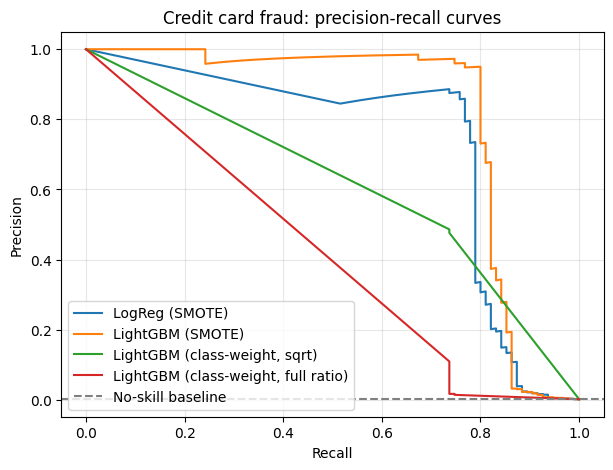

In [28]:
plot_pr_curves(y_test_cc, probas, "Credit card fraud: precision-recall curves")

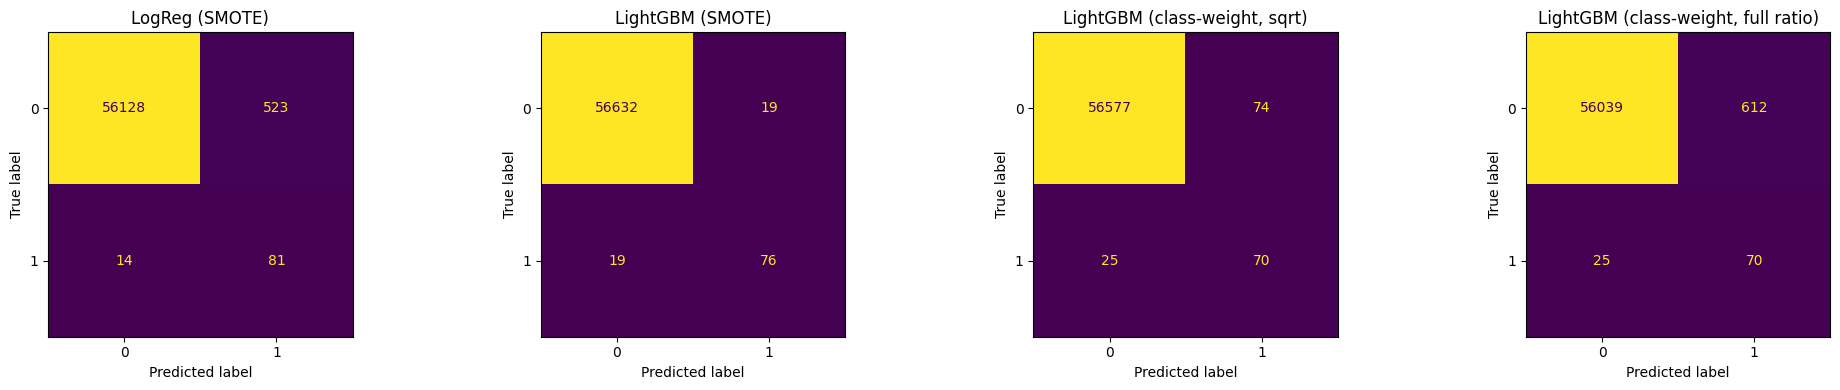

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, len(probas), figsize=(5 * len(probas), 4))
for ax, (name, p) in zip(axes, probas.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_cc, (p >= 0.5).astype(int), ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [30]:
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

joblib.dump(logreg, MODELS_DIR / "creditcard_logreg.pkl")
joblib.dump(lgbm_smote, MODELS_DIR / "creditcard_lgbm_smote.pkl")
joblib.dump(lgbm_weighted, MODELS_DIR / "creditcard_lgbm_weighted.pkl")
cc_results.to_csv(RESULTS_DIR / "creditcard_results.csv")
print("Saved models and results.")

Saved models and results.
